# 05 — Spatial and descriptive overview

Descriptive overview of the cleaned 2025 data, produced after modelling. No modelling decisions were based on these figures.

Plotting helpers live in `src/figures.py`; this notebook only calls them.

In [1]:
import sys
from pathlib import Path

# The notebook runs from notebooks/; make the project root importable.
sys.path.insert(0, str(Path.cwd().parent))

from src.load import load_raw
from src.clean import load_processed, apply_rules
from src import figures

In [2]:
amb = load_processed()                          # ambulances, R1-R7
engine, _ = apply_rules(load_raw(), {"ENGINE"})  # comparison only, R2-R5 (as in Stage 1)
calls = figures.calls_by_priority(amb)
print(f"ambulance rows: {len(amb):,}   ambulance calls: {len(calls):,}   engine rows: {len(engine):,}")

ambulance rows: 100,461   ambulance calls: 99,580   engine rows: 52,538


## Fig 1 — process timeline

Prediction moment = this unit's dispatch.

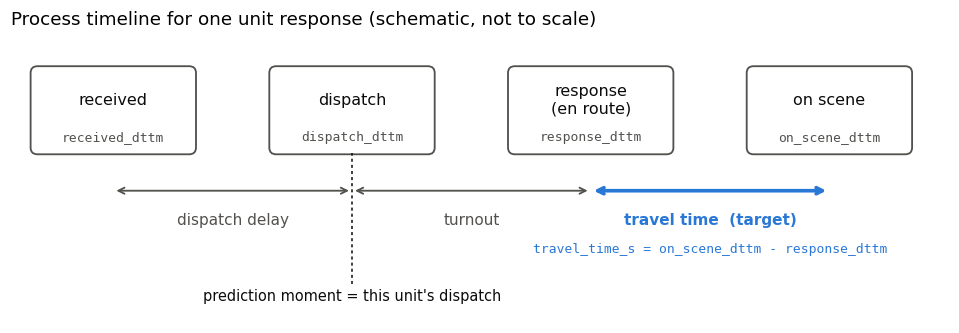

In [3]:
fig_paths = [figures.process_timeline()]

## Fig 2 — ambulance calls by priority: points and kernel density

One point per `call_number`. Right panels: kernel density of call locations (descriptive smoothing, scaled 0–1 per panel); locations are intersection-level. Gaussian kernel, bandwidth by Scott's rule (`scipy.stats.gaussian_kde`), computed in local km so the kernel is round in distance, not in degrees. Layout follows Bayisa et al. (2023), Fig. 2.

calls per priority: {'Code 3': '44,290', 'Code 2': '34,732'}


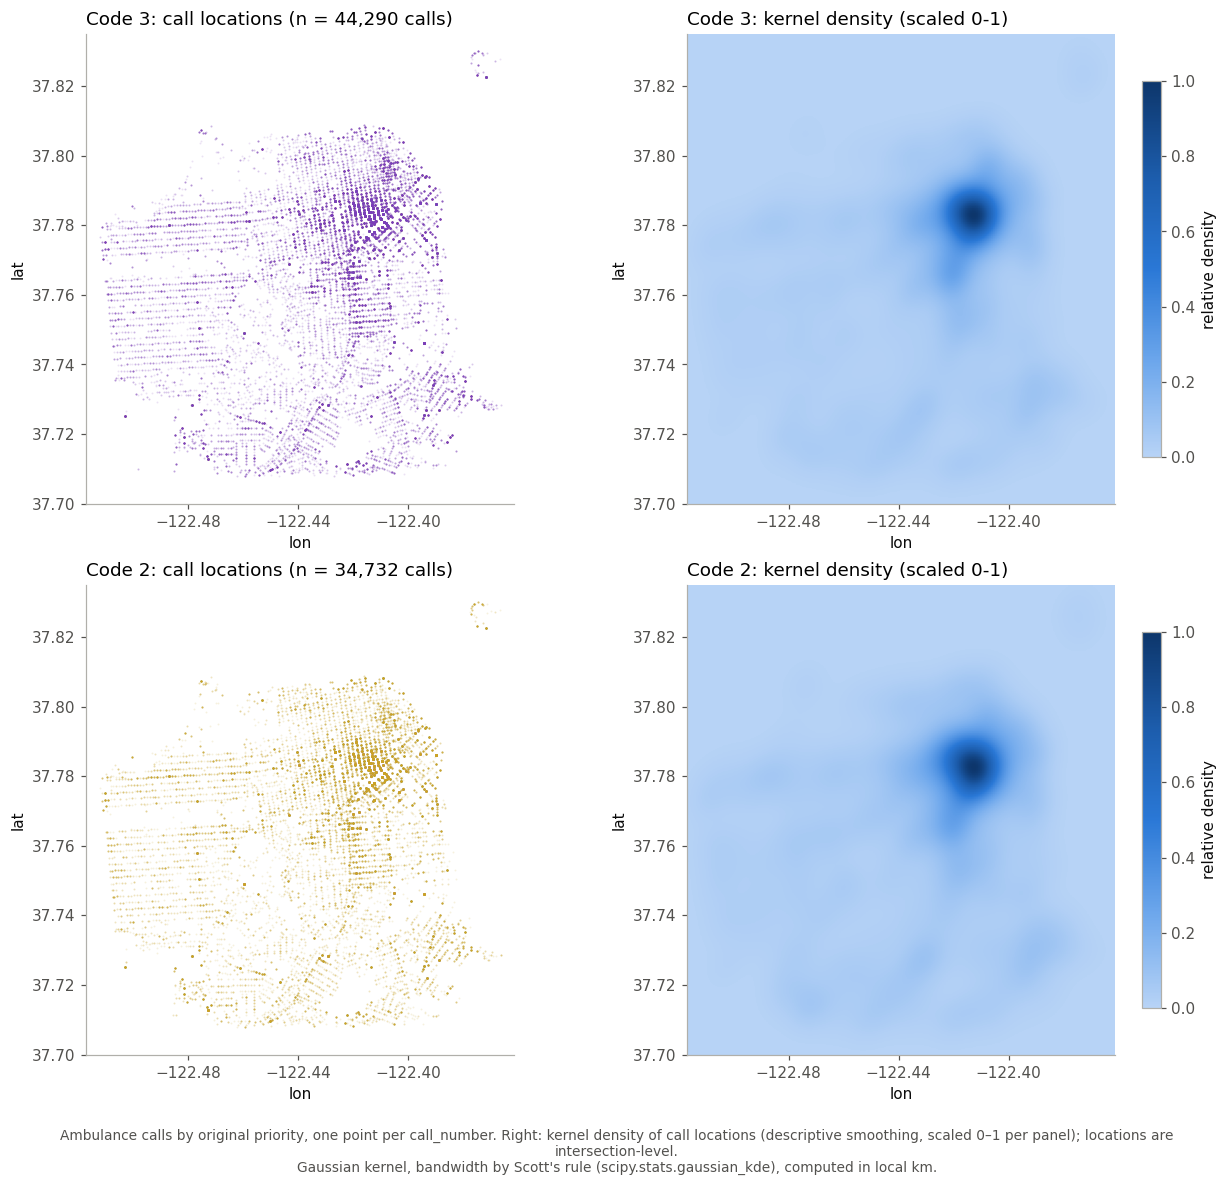

In [4]:
path, call_counts = figures.priority_point_kde(calls)
fig_paths.append(path)
print("calls per priority:", {k: f"{v:,}" for k, v in call_counts.items()})

## Fig 3 — empirical CDFs of travel time

Rows are unit responses, as in `reports/stage1_diagnostics.txt`. Stage 1 medians were computed **before** R6/R7 (R1–R5 only); this notebook uses the final R1–R7 data for ambulances, so small differences are expected. ENGINE is R2–R5 in both. Stage 1 did not report a median for the pooled "other" priority group.

,median_s (fig 3),"median_s (stage1, R1-R5)",diff_s
ENGINE,174.0,174.0,0.0
MEDIC,474.0,473.0,1.0
PRIVATE,424.0,423.0,1.0
Code 3,346.0,346.0,0.0
Code 2,689.0,689.0,0.0
other,504.0,NaN,NaN


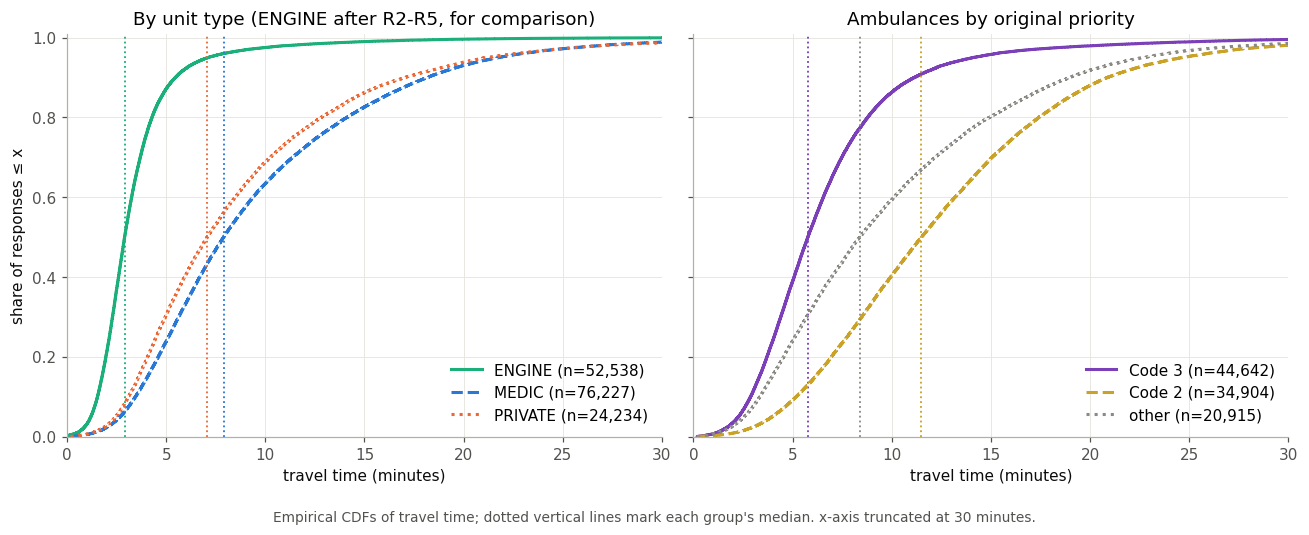

In [5]:
import pandas as pd

path, medians = figures.travel_time_ecdfs(amb, engine)
fig_paths.append(path)
# Values copied from reports/stage1_diagnostics.txt (sections 3c and 4).
stage1 = {"ENGINE": 174.0, "MEDIC": 473.0, "PRIVATE": 423.0, "Code 3": 346.0, "Code 2": 689.0, "other": None}
comparison = pd.DataFrame({"median_s (fig 3)": medians, "median_s (stage1, R1-R5)": stage1})
comparison["diff_s"] = comparison.iloc[:, 0] - comparison.iloc[:, 1]
comparison

## Fig 4 — hexbin map of median ambulance travel time

Gridsize is the largest value for which the median non-empty hexagon still holds ≥ 30 ambulance responses. Hexagons with fewer than 30 responses are hidden (`mincnt=30`).

gridsize = 44 (median responses per non-empty hex = 32)


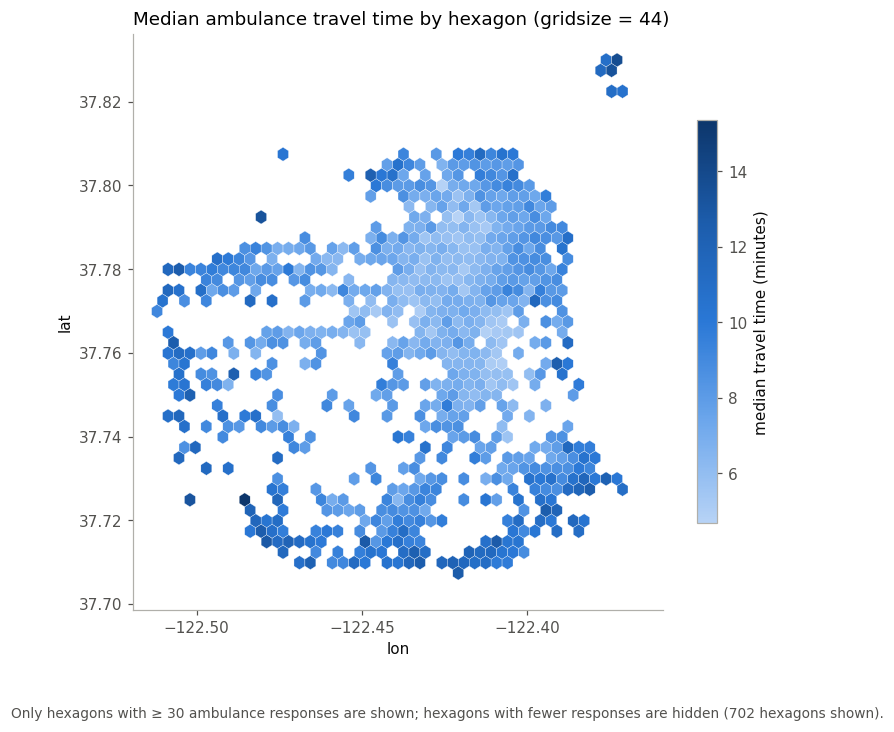

In [6]:
gridsize, median_count = figures.choose_hex_gridsize(amb, min_count=30)
print(f"gridsize = {gridsize} (median responses per non-empty hex = {median_count:.0f})")
fig_paths.append(figures.median_travel_hexbin(amb, gridsize, min_count=30))

In [7]:
for p in fig_paths:
    print(p.relative_to(Path.cwd().parent))

reports/figures/08_process_timeline.png
reports/figures/09_priority_points_kde.png
reports/figures/10_travel_time_ecdfs.png
reports/figures/11_median_travel_hexbin.png
